In [ ]:
import numpy as np
import pandas as pd
import pulp
import matplotlib.pyplot as plt

In [4]:
weapons = ["spear", "sword"]
price = [100, 5]

beskar_needed = [1, 0.5]
tungsten_needed = [1, 1]
titanium_needed = [3, 1]

total_beskar = 125
total_tungsten = 225
total_titanium = 300

swords_demand = 100

In [6]:
def solve_making_weapons(weapons, price, beskar_needed, tungsten_needed, titanium_needed, total_beskar, total_tungsten, total_titanium, swords_demand):
    model = pulp.LpProblem("Weapon_Production", pulp.LpMaximize)

    x = model.add_variable_dicts("x", weapons, lowBound=0, cat='Continuous')

    #Constarints
    model += pulp.lpSum([price[i] * x[weapons[i]] for i in range(len(weapons))]), "Total_Profit"

    model += pulp.lpSum([beskar_needed[i] * x[weapons[i]] for i in range(len(weapons))]) <= total_beskar, "Beskar_Constraint"
    model += pulp.lpSum([tungsten_needed[i] * x[weapons[i]] for i in range(len(weapons))]) <= total_tungsten, "Tungsten_Constraint"
    model += pulp.lpSum([titanium_needed[i] * x[weapons[i]] for i in range(len(weapons))]) <= total_titanium, "Titanium_Constraint"
    model += x["sword"] >= swords_demand, "Swords_Demand_Constraint"

    result = model.solve(pulp.HiGHS(msg=False))

    return model, x, result


In [8]:
model, x, result = solve_making_weapons(weapons, price, beskar_needed, tungsten_needed, titanium_needed, total_beskar, total_tungsten, total_titanium, swords_demand)

if result.status_str == "Optimal":
    print("Optimal solution found:")
    for weapon in weapons:
        print(f"{weapon}: {x[weapon].varValue}")
    print(f"Total Profit: {pulp.value(model.objective)}")

Optimal solution found:
spear: 66.66666666666667
sword: 100.0
Total Profit: 7166.666666666667


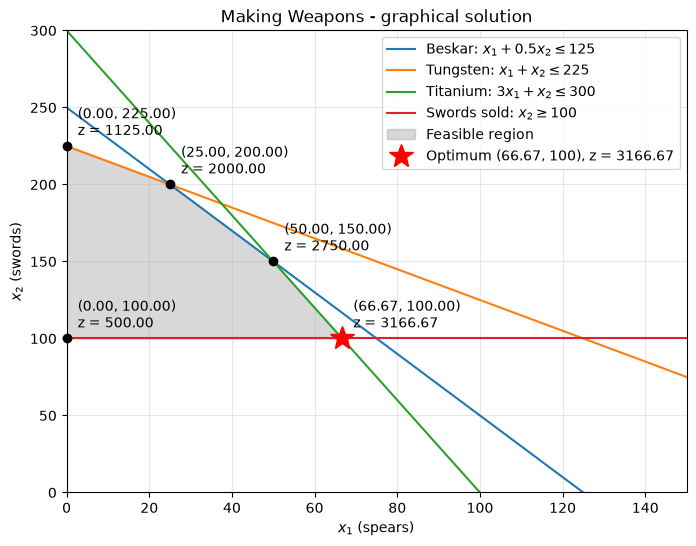

In [9]:
x1 = np.linspace(0, 150, 400)

# Each constraint written as x2 = ... (its boundary line)
beskar = (125 - x1) / 0.5         # x1 + 0.5*x2 <= 125
tungsten = 225 - x1               # x1 + x2 <= 225
titanium = 300 - 3 * x1           # 3*x1 + x2 <= 300

fig, ax = plt.subplots(figsize=(8, 6))

# 1. Constraint boundary lines
ax.plot(x1, beskar, label=r"Beskar: $x_1 + 0.5x_2 \leq 125$")
ax.plot(x1, tungsten, label=r"Tungsten: $x_1 + x_2 \leq 225$")
ax.plot(x1, titanium, label=r"Titanium: $3x_1 + x_2 \leq 300$")
ax.axhline(100, color="tab:red", label=r"Swords sold: $x_2 \geq 100$")

# 2. Feasible region: above x2 = 100 and below all three material lines
x1_feasible = np.linspace(0, 200 / 3, 200)
upper = np.minimum.reduce([(125 - x1_feasible) / 0.5, 225 - x1_feasible, 300 - 3 * x1_feasible])
ax.fill_between(x1_feasible, 100, upper, color="grey", alpha=0.3, label="Feasible region")

# 3. Corner points of the feasible region and the revenue at each
corners = [(0, 100), (200 / 3, 100), (50, 150), (25, 200), (0, 225)]
for cx, cy in corners:
    z = 40 * cx + 5 * cy
    ax.plot(cx, cy, "ko", clip_on=False)
    ax.annotate(f"({cx:.2f}, {cy:.2f})\nz = {z:.2f}", (cx, cy), textcoords="offset points", xytext=(8, 8))

# 4. Optimum
ax.plot(200 / 3, 100, "r*", markersize=18, clip_on=False, label="Optimum (66.67, 100), z = 3166.67")

ax.set_xlim(0, 150)
ax.set_ylim(0, 300)
ax.set_xlabel("$x_1$ (spears)")
ax.set_ylabel("$x_2$ (swords)")
ax.set_title("Making Weapons - graphical solution")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
plt.show()